## 05 · Module cross-repression (Gate 3)

Test the bifurcation signature directly: within the **Mixed hub**, correlate every Gast/pSom module gene (Gast OR pSom) against the Gast and pSom module scores, then measure the mutual correlation between the two gene-loading vectors. A negative *r* means genes that load onto Gast anti-load onto pSom — competitive cross-repression. This is the Gate-3 readout.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth       = os.path.join(*(['..']*4))
pth_data  = os.path.join(pth, 'data')
pth_in    = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat  = os.path.join(pth_data, 'features', 'biomart')
pth_out   = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [3]:
c_dict = {
    'Gast' : plt.cm.tab20c(12),
    'pSom' : plt.cm.tab20c(8),
    'Both' : 'darkgrey'}

In [4]:
# load signatures data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad')); adata

Out[14]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [5]:
# select module genes — Gast OR pSom (union)
get_feat = lambda pth: pd.read_csv(pth).hsapiens
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = (pd.merge(gast, psom, 'outer').hsapiens.drop_duplicates())
g = g.loc[g.isin(adata.var_names)]
print('union genes on manifold:', g.size)

union genes on manifold: 139


In [6]:
# select the cell-state convergence hub
msk = (adata.obs.celltype == 'Mixed')
adata_plt = adata[msk, g].copy()
adata_plt

Out[16]: 
AnnData object with n_obs × n_vars = 4888 × 139
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 4888 × 139
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [7]:
# compute per-gene module correlations -> rank
X = pd.DataFrame(np.asarray(adata_plt.X), index = adata_plt.obs_names, columns = g)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.GSE162534.values[:, None]  # Gast
mod2 = adata_plt.obs.GSE229103.values[:, None]  # pSom
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

In [8]:
# assign module labels — Gast | pSom | Both
ix = R.index
msk_dict = {
    'Gast' : ix.isin(gast) & ~ix.isin(psom),
    'pSom' : ~ix.isin(gast) & ix.isin(psom),
    'Both' : ix.isin(gast) & ix.isin(psom)}
for mod, m in msk_dict.items():
    R.loc[m, 'Module'] = mod
    print(mod, int(m.sum()))
R['Module'] = pd.Categorical(R.Module, reversed(list(msk_dict.keys())), ordered = True)

Gast 51
pSom 63
Both 25


In [9]:
# compute the module mutual correlation (Gate 3 statistic)
rval = np.corrcoef(*R.loc[~msk_dict['Both'], ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('r =', rval)

r = -0.54


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/modules.pdf


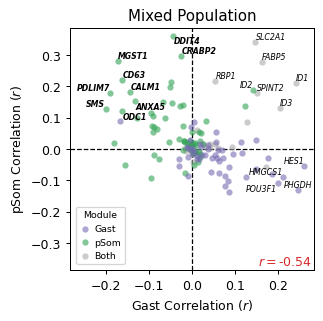

In [10]:
# plot gene-module correlations — scatter
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

n, texts = 20, list()
for i in R.head(n).index:
    xi = R.loc[i].Gast; yi = R.loc[i].pSom
    fw = 'bold' if (xi < 0) and (yi > 0) else 'normal'
    texts.append(ax.text(xi, yi, i, fontsize = 6.25, fontstyle = 'italic', fontweight = fw))
adjust_text(texts = texts)

leg = ax.legend(title = 'Module', loc = 'lower left', title_fontsize = 7.5,
                handlelength = 1, handletextpad = .5, borderaxespad = .65,
                fontsize = 7.5, reverse = True)
ax.text(.99, .01, r'$r=$' + f'{rval}', transform = ax.transAxes,
        fontsize = 10, color = 'tab:red', ha = 'right', va = 'bottom')
ax.set_title('Mixed Population')
ax.set_xlabel(r'Gast Correlation ($r$)')
ax.set_ylabel(r'pSom Correlation ($r$)')
fn = os.path.join(pth_out, 'modules.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)